In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc
import os

In [ ]:
def parse_comsol_edge_data(filepath,var_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% R;Z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')

    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}

    df = pd.DataFrame(index=range(len(columns)),columns=['param_name']+var_names)

    for i, col in enumerate(columns):
        #print('col:' + col)
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            vars=conditions.split(',')

            
            
            df.at[i, 'param_name'] = param_name


            for k,var in enumerate(vars):
                if '=' in var:
                    key, value = var.split('=')
                    key = key.strip()
                    value = value.strip()
                    #print(f"Condition: {key} = {float(value)}")
                    df.at[i, var_names[k]] = float(value)
                else:
                    #print(f"Condition: {var_names[k]} : {var}")
                    df.at[i, var_names[k]] = var
        else:
            # Coordinate columns (r, z)
            df.at[i, 'param_name'] = col.strip()
            for k,var in enumerate(var_names):
                df.at[i, var_names[k]] = None
            
        
    data_lines = lines[data_start:]
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)

    # # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=['R','Z']+columns[2:])

    # Create new dataframe that will be the final export
    # params = df['param_name'].dropna().unique()
    #print(params.tolist()+var_names)

    # # Read the data

    params = df['param_name'].dropna().unique()

    params_list = params
    params_list = params_list[2:]
    #print(params.tolist()+var_names)
    columns = params.tolist()+var_names

    # find unique values of each parameter
    df_vars = df.drop('param_name',axis=1)
    df_unique_vars= df_vars.drop_duplicates(keep='first').dropna(how='all')

    #print('Number of rows in new dataframe')
    n_rows = df_raw.shape[0]*np.shape(df_unique_vars)[0]
    #print(n_rows)

    output_df = pd.DataFrame(index=range(n_rows),columns=columns)
    #print('Number of unique variables:' ,np.shape(df_unique_vars))


    param = params_list[0]
    for param in params_list:
        row_idx = 0
        for idx, row in df_unique_vars.iterrows():
            
            
                #print('loop start')
                #print(f"Processing param: {param}")
                #print(f"Processing param: {param}")
                row['param_name'] = param

                # find which rows in df match this row 
                mask = (df[row.index] == row.values).all(axis=1)
                matching_rows = df[mask]
                for raw_idx, raw_row in df_raw.iterrows():
                    value=raw_row.iloc[matching_rows.index.to_list()[0]]
                    #print(df.columns)
                    r = raw_row['R']
                    z = raw_row['Z']

                    output_df.at[row_idx, 'R'] = r
                    output_df.at[row_idx, 'Z'] = z
                    
                    for var_name in var_names:
                        #print(row_idx,var_name)
                        output_df.at[row_idx, var_name] = row[var_name]  
                    output_df.at[row_idx, param] = value 
                    row_idx += 1

    new_names = []
    for i,name in enumerate(output_df.columns):
        
        new_names.append(name.split(' ')[0])

    output_df.columns = new_names

    return output_df



In [7]:
filepath = '/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/max_C_r_vary.txt'
with open(filepath, 'r') as file:
    lines = file.readlines()

# Find the header line with column names
header_line = None
data_start = None



for i, line in enumerate(lines):
    if line.startswith('% Data'):
        header_line = line.strip()
        data_start = i + 1

        var = header_line.split('@')[1].replace('abs', '').replace(')', '').replace('(', '')
        parms = header_line.split('@')[1]
        for param in parms.split(','):
            if '=' in param:
                
                name,value = param.split('=')[0],param.replace(')', '').split('=')[1]
            else:
                name,value = 'composition',param
            print(f"{name} = {value}")
        data_value = float(lines[i+1])
        var_name, var_value = var,data_value
        print(f"{var_name} = {var_value}")
        print(parms)
        print(data_start)

% Data (abs(solid.RotrZ) (rad) @ Q_in=20, C_R=5, Montserrat, h2oc=3, Xcph=0.4, nu_c_max=10000, Sb_option=0, tau_Xc=1E-8, param_def=0)
 Q_in = 20
 C_R = 5
composition =  Montserrat
 h2oc = 3
 Xcph = 0.4
 nu_c_max = 10000
 Sb_option = 0
 tau_Xc = 1E-8
 param_def = 0
 Q_in=20, C_R=5, Montserrat, h2oc=3, Xcph=0.4, nu_c_max=10000, Sb_option=0, tau_Xc=1E-8, param_def=0)
11


In [10]:
import pandas as pd
import numpy as np

def read_comsol_alternating_blocks(filepath):
    records = {}

    with open(filepath, "r") as f:
        lines = [ln.strip() for ln in f if ln.strip()]

    i = 0
    while i < len(lines):
        line = lines[i]

        if not line.startswith("% Data"):
            i += 1
            continue

        header = line[1:].strip()
        left, right = header.split("@", 1)

        var_name = left.replace("Data", "").strip()

        params = {}
        for token in right.split(","):
            token = token.strip().rstrip(")")
            if "=" in token:
                name, value = token.split("=", 1)
                params[name.strip()] = pd.to_numeric(value.strip(), errors="ignore")
            else:
                params["composition"] = token

        key = tuple(sorted(params.items()))

        j = i + 1
        while j < len(lines) and not lines[j].startswith("% Data"):
            try:
                var_value = float(lines[j])
            except ValueError:
                break

            if key not in records:
                records[key] = dict(params)

            records[key][var_name] = var_value
            j += 1

        i = j

    df = pd.DataFrame(list(records.values()))
    return df

In [47]:
filepath = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/max_C_r_vary.txt"
df = read_comsol_alternating_blocks(filepath)
df.head()
filepath_tilt500 = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/tilt500_C_r_vary.txt"
df_tilt500 = read_comsol_alternating_blocks(filepath_tilt500)
cols = df_tilt500.columns
cols = list(cols)
cols[-1] = 'tilt500'
df_tilt500.columns = cols
df_tilt500.head()
filepath_inlet = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/inlet_C_r_vary.txt"
df_inlet = read_comsol_alternating_blocks(filepath_inlet)
cols = df_inlet.columns
cols = list(cols)
cols[-1] = 'P_inlet'
df_inlet.columns = cols
df_inlet.head()
param_cols = [c for c in df.columns if c in df_tilt500.columns]
value_col_df = [c for c in df.columns if c not in param_cols][0]
value_col_tilt = [c for c in df_tilt500.columns if c not in param_cols][0]


df_merged = df.merge(
df_tilt500[param_cols + [value_col_tilt]],
on=param_cols,
how="left",
suffixes=("", "_tilt500")
)

value_col_inlet = [c for c in df_inlet.columns if c not in param_cols][0]
inlet_key_cols = [c for c in param_cols if c != "param_def"]

value_col_inlet = [c for c in df_inlet.columns if c not in inlet_key_cols][0]

df_merged_C_R = df_merged.merge(
    df_inlet[inlet_key_cols + [value_col_inlet]],
    on=inlet_key_cols,
    how="left",
    suffixes=("", "_inlet")
)




/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_11436/2282354476.py:28: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  params[name.strip()] = pd.to_numeric(value.strip(), errors="ignore")


In [50]:
filepath = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/max_Xcph_vary.txt"
df_Xcph = read_comsol_alternating_blocks(filepath)
df_Xcph.head()
filepath_tilt500 = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/tilt500_Xcph_vary.txt"
df_Xcph_tilt500 = read_comsol_alternating_blocks(filepath_tilt500)
cols = df_Xcph_tilt500.columns
cols = list(cols)

print(cols)
cols[-1] = 'tilt500'
df_Xcph_tilt500.columns = cols
df_Xcph_tilt500.head()
filepath_inlet = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/inlet_Xcph_vary.txt"
df_Xcph_inlet = read_comsol_alternating_blocks(filepath_inlet)
cols = df_Xcph_inlet.columns
cols = list(cols)
cols[-1] = 'P_inlet'
df_Xcph_inlet.columns = cols
df_Xcph_inlet.head()
param_cols = [c for c in df_Xcph.columns if c in df_Xcph_tilt500.columns]
value_col_df = [c for c in df_Xcph.columns if c not in param_cols][0]
value_col_tilt = [c for c in df_Xcph_tilt500.columns if c not in param_cols][0]


df_merged = df_Xcph.merge(
df_Xcph_tilt500[param_cols + [value_col_tilt]],
on=param_cols,
how="left",
suffixes=("", "_tilt500")
)

value_col_inlet = [c for c in df_Xcph_inlet.columns if c not in param_cols][0]
inlet_key_cols = [c for c in param_cols if c != "param_def"]

value_col_inlet = [c for c in df_Xcph_inlet.columns if c not in inlet_key_cols][0]

df_merged_Xcph = df_merged.merge(
    df_Xcph_inlet[inlet_key_cols + [value_col_inlet]],
    on=inlet_key_cols,
    how="left",
    suffixes=("", "_inlet")
)




['Q_in', 'C_R', 'composition', 'h2oc', 'Xcph', 'nu_c_max', 'Sb_option', 'tau_Xc', '(solid.RotrZ (rad)']


/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_11436/2282354476.py:28: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  params[name.strip()] = pd.to_numeric(value.strip(), errors="ignore")


In [51]:
df_Xcph_tilt500

,Q_in,C_R,composition,h2oc,Xcph,nu_c_max,Sb_option,tau_Xc,tilt500
0,20,15,Montserrat,3,0.10,10000,0,1.000000e-08,0.000007
1,20,15,Montserrat,3,0.15,10000,0,1.000000e-08,0.000007
2,20,15,Montserrat,3,0.20,10000,0,1.000000e-08,0.000008
3,20,15,Montserrat,3,0.25,10000,0,1.000000e-08,0.000009
4,20,15,Montserrat,3,0.30,10000,0,1.000000e-08,0.000009
5,20,15,Montserrat,3,0.35,10000,0,1.000000e-08,0.000010
6,20,15,Montserrat,3,0.40,10000,0,1.000000e-08,0.000011
7,20,15,Montserrat,3,0.45,10000,0,1.000000e-08,0.000013
8,20,15,Montserrat,3,0.50,10000,0,1.000000e-08,0.000015
9,20,15,Montserrat,3,0.55,10000,0,1.000000e-08,0.000017


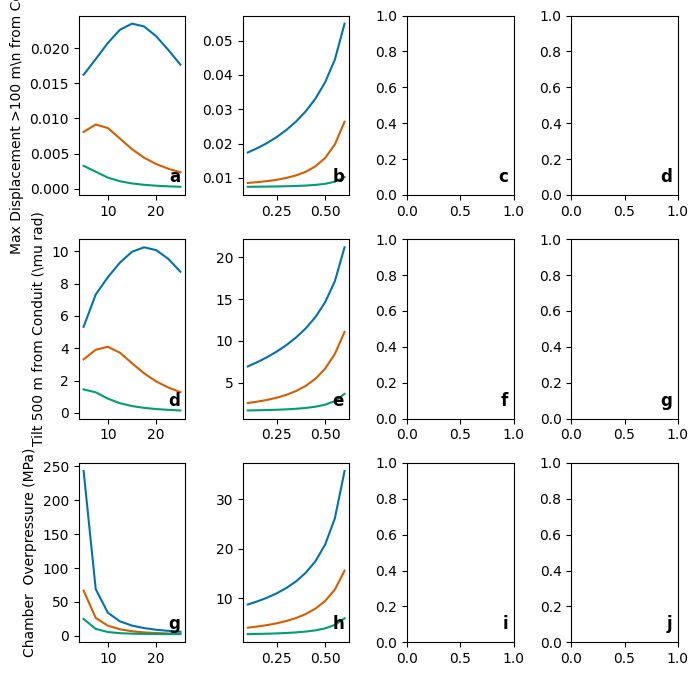

In [52]:
import matplotlib.gridspec as gridspec

color_list = ['#0072B2', '#D55E00', '#009E73']  # blue, orange, green






fig,axes = plt.subplots(3,4,figsize=(7, 7))

axes[0,0].set_ylabel('Max Displacement >100 m\\n from Conduit')
axes[1,0].set_ylabel('Tilt 500 m from Conduit (\mu rad)')
axes[2,0].set_ylabel('Chamber  Overpressure (MPa)')

axes[2,0].set_xlabel('Conduit Radius (m)')
axes[2,1].set_xlabel('Crystal Volume Fraction (X_c)')
# vary C_R get max value for each composition and plot against C_R
for i, composition in enumerate(df_merged_C_R['composition'].unique()):
    # column 1 is C_R 
    df_comp = df_merged_C_R[(df_merged_C_R['composition'] == composition)&(df_merged_C_R['param_def']==1)]
    max_value = df_comp['(abs(solid.disp) (m)']
    c_r = df_comp['C_R']
    
    tilt_500_value = df_comp['tilt500']*1e6

    p_inlet = df_comp['P_inlet']/1e6

    axes[0,0].plot(c_r, max_value, label=f'{composition}', color=color_list[i])
    axes[1,0].plot(c_r, tilt_500_value, label=f'{composition}', color=color_list[i])
    axes[2,0].plot(c_r, p_inlet*np.ones_like(c_r), label=f'{composition}', color=color_list[i])
    # Column 2 is Xcph
    df_comp = df_merged_Xcph[(df_merged_Xcph['composition'] == composition)]
    x_cph = df_comp['Xcph']
    max_value = df_comp['(abs(solid.disp) (m)']
    tilt_500_value = df_comp['tilt500']*1e6
    p_inlet = df_comp['P_inlet']/1e6
    axes[0,1].plot(x_cph, max_value, label=f'{composition}', color=color_list[i])
    axes[1,1].plot(x_cph, tilt_500_value, label=f'{composition}', color=color_list[i])
    axes[2,1].plot(x_cph, p_inlet*np.ones_like(x_cph), label=f'{composition}', color=color_list[i])
    


# Label each subplot with a letter in the bottom right corner
for i, row_axes in enumerate(axes):
    for j, ax in enumerate(row_axes):
        label = chr(97 + i*3 + j)  # Generate labels a, b, c, ...
        ax.text(0.95, 0.05, label, transform=ax.transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right')


plt.tight_layout(rect=[0, 0, 1, 0.98])


# save as pdf 


In [57]:
filepath = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/max_Cw_vary.txt"
df_Cw= read_comsol_alternating_blocks(filepath)
df_Cw.head()



filepath_tilt500 = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/tilt500_Cw_vary.txt"
df_Cw_tilt500 = read_comsol_alternating_blocks(filepath_tilt500)
cols = df_Cw_tilt500.columns
cols = list(cols)

print(cols)
cols[-1] = 'tilt500'
df_Cw_tilt500.columns = cols
df_Cw_tilt500.head()
filepath_inlet = "/Users/elioteaton/Documents/Paper_1_models/April 2026 attempt/broad_comparison/inlet_Cw_vary.txt"
df_Cw_inlet = read_comsol_alternating_blocks(filepath_inlet)
cols = df_Cw_inlet.columns
cols = list(cols)
cols[-1] = 'P_inlet'
df_Cw_inlet.columns = cols
df_Cw_inlet.head()
param_cols = [c for c in df_Cw.columns if c in df_Cw_tilt500.columns]
value_col_df = [c for c in df_Cw.columns if c not in param_cols][0]
value_col_tilt = [c for c in df_Cw_tilt500.columns if c not in param_cols][0]


df_merged = df_Cw.merge(
df_Cw_tilt500[param_cols + [value_col_tilt]],
on=param_cols,
how="left",
suffixes=("", "_tilt500")
)

value_col_inlet = [c for c in df_Cw_inlet.columns if c not in param_cols][0]
inlet_key_cols = [c for c in param_cols if c != "param_def"]

value_col_inlet = [c for c in df_Cw_inlet.columns if c not in inlet_key_cols][0]

df_merged_Cw = df_merged.merge(
    df_Cw_inlet[inlet_key_cols + [value_col_inlet]],
    on=inlet_key_cols,
    how="left",
    suffixes=("", "_inlet")
)



/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_11436/2282354476.py:28: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  params[name.strip()] = pd.to_numeric(value.strip(), errors="ignore")


['Q_in', 'C_R', 'composition', 'h2oc', 'Xcph', 'nu_c_max', 'Sb_option', 'tau_Xc', '(solid.RotrZ (rad)']


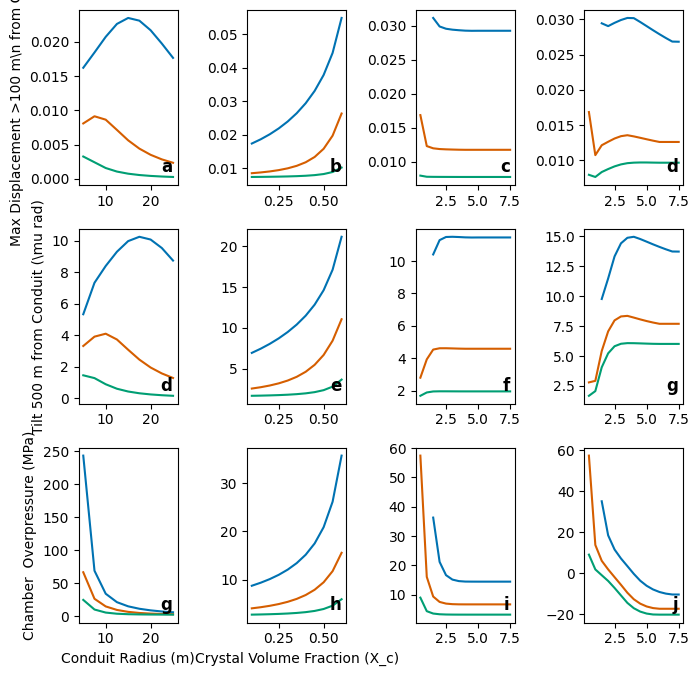

In [58]:
import matplotlib.gridspec as gridspec

color_list = ['#0072B2', '#D55E00', '#009E73']  # blue, orange, green


fig,axes = plt.subplots(3,4,figsize=(7, 7))

axes[0,0].set_ylabel('Max Displacement >100 m\\n from Conduit')
axes[1,0].set_ylabel('Tilt 500 m from Conduit (\mu rad)')
axes[2,0].set_ylabel('Chamber  Overpressure (MPa)')

axes[2,0].set_xlabel('Conduit Radius (m)')
axes[2,1].set_xlabel('Crystal Volume Fraction (X_c)')
# vary C_R get max value for each composition and plot against C_R
for i, composition in enumerate(df_merged_C_R['composition'].unique()):
    # column 1 is C_R 
    df_comp = df_merged_C_R[(df_merged_C_R['composition'] == composition)&(df_merged_C_R['param_def']==1)]
    max_value = df_comp['(abs(solid.disp) (m)']
    c_r = df_comp['C_R']
    
    tilt_500_value = df_comp['tilt500']*1e6

    p_inlet = df_comp['P_inlet']/1e6

    axes[0,0].plot(c_r, max_value, label=f'{composition}', color=color_list[i])
    axes[1,0].plot(c_r, tilt_500_value, label=f'{composition}', color=color_list[i])
    axes[2,0].plot(c_r, p_inlet*np.ones_like(c_r), label=f'{composition}', color=color_list[i])
    
    
    # Column 2 is Xcph
    df_comp = df_merged_Xcph[(df_merged_Xcph['composition'] == composition)]
    x_cph = df_comp['Xcph']
    max_value = df_comp['(abs(solid.disp) (m)']
    tilt_500_value = df_comp['tilt500']*1e6
    p_inlet = df_comp['P_inlet']/1e6
    axes[0,1].plot(x_cph, max_value, label=f'{composition}', color=color_list[i])
    axes[1,1].plot(x_cph, tilt_500_value, label=f'{composition}', color=color_list[i])
    axes[2,1].plot(x_cph, p_inlet*np.ones_like(x_cph), label=f'{composition}', color=color_list[i])
    
    # Column 3 is Cw with Sb 0 
    df_comp = df_merged_Cw[(df_merged_Cw['composition'] == composition)&(df_merged_Cw['Sb_option']==0)]
    c_w = df_comp['h2oc']
    max_value = df_comp['(abs(solid.disp) (m)']
    tilt_500_value = df_comp['tilt500']*1e6
    p_inlet = df_comp['P_inlet']/1e6
    axes[0,2].plot(c_w, max_value, label=f'{composition}', color=color_list[i])
    axes[1,2].plot(c_w, tilt_500_value, label=f'{composition}', color=color_list[i])
    axes[2,2].plot(c_w, p_inlet*np.ones_like(c_w), label=f'{composition}', color=color_list[i])

    #column 4 is Cw with Sb 6
    df_comp = df_merged_Cw[(df_merged_Cw['composition'] == composition)&(df_merged_Cw['Sb_option']==6)]
    c_w = df_comp['h2oc']
    max_value = df_comp['(abs(solid.disp) (m)']
    tilt_500_value = df_comp['tilt500']*1e6
    p_inlet = df_comp['P_inlet']/1e6
    axes[0,3].plot(c_w, max_value, label=f'{composition}', color=color_list[i])
    axes[1,3].plot(c_w, tilt_500_value, label=f'{composition}', color=color_list[i])
    axes[2,3].plot(c_w, p_inlet*np.ones_like(c_w), label=f'{composition}', color=color_list[i])
# Label each subplot with a letter in the bottom right corner
for i, row_axes in enumerate(axes):
    for j, ax in enumerate(row_axes):
        label = chr(97 + i*3 + j)  # Generate labels a, b, c, ...
        ax.text(0.95, 0.05, label, transform=ax.transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right')


plt.tight_layout(rect=[0, 0, 1, 0.98])



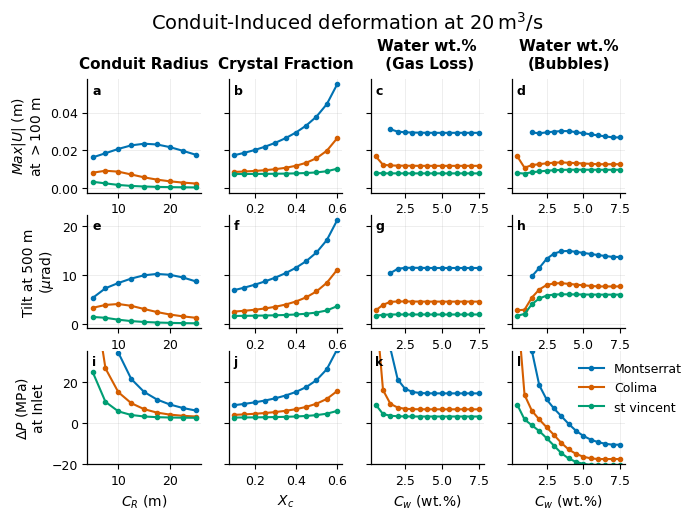

In [82]:
# Publication-style multi-panel figure (square subplots, shared y per row)
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# Style tuned for manuscript readability
mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.9,
})

# Keep user-defined palette
color_list = ['#0072B2', '#D55E00', '#009E73']  # blue, orange, green
compositions = list(df_merged_C_R["composition"].dropna().unique())

# Thicker lines and larger markers for publication
line_width = 1.5
marker_size = 3

# Square panels: 4 columns x 3 rows
fig, axes = plt.subplots(
    3, 4,
    figsize=(7, 5),
    sharey="row",
    constrained_layout=False
)

# Enforce square axes in every panel
for ax in axes.ravel():
    ax.set_box_aspect(1)

col_titles = [
    r"Conduit Radius",
    r"Crystal Fraction",
    r"Water wt.%"+"\n (Gas Loss)",
    r"Water wt.%"+"\n(Bubbles)",
]
for j, title in enumerate(col_titles):
    axes[0, j].set_title(title, pad=8, weight="bold")

row_labels = [
    r"$Max|U|$ (m)" + '\n'+ r"at $> 100$ m",
    r"Tilt at 500 m" + "\n"+r"($\mu$rad)",
    r"$\Delta P$ (MPa)"+"\n"+ "at Inlet",
]
for i, yl in enumerate(row_labels):
    axes[i, 0].set_ylabel(yl)

# x labels only on bottom row for a cleaner look
axes[2, 0].set_xlabel(r"$C_R$ (m)")
axes[2, 1].set_xlabel(r"$X_c$")
axes[2, 2].set_xlabel(r"$C_w$ (wt.%)")
axes[2, 3].set_xlabel(r"$C_w$ (wt.%)")

for i, comp in enumerate(compositions):
    c = color_list[i % len(color_list)]

    # Column 1: C_R (use param_def == 1)
    d1 = df_merged_C_R[(df_merged_C_R["composition"] == comp) & (df_merged_C_R["param_def"] == 1)].copy()
    d1 = d1.sort_values("C_R")
    x = d1["C_R"].to_numpy()
    y_disp = d1["(abs(solid.disp) (m)"].to_numpy()
    y_tilt = (d1["tilt500"] * 1e6).to_numpy()
    y_pin = (d1["P_inlet"] / 1e6).to_numpy()

    axes[0, 0].plot(x, y_disp, "-o", lw=line_width, ms=marker_size, color=c, label=comp)
    axes[1, 0].plot(x, y_tilt, "-o", lw=line_width, ms=marker_size, color=c)
    axes[2, 0].plot(x, y_pin, "-o", lw=line_width, ms=marker_size, color=c)

    # Column 2: Xcph
    d2 = df_merged_Xcph[df_merged_Xcph["composition"] == comp].copy()
    d2 = d2.sort_values("Xcph")
    x = d2["Xcph"].to_numpy()
    y_disp = d2["(abs(solid.disp) (m)"].to_numpy()
    y_tilt = (d2["tilt500"] * 1e6).to_numpy()
    y_pin = (d2["P_inlet"] / 1e6).to_numpy()

    axes[0, 1].plot(x, y_disp, "-o", lw=line_width, ms=marker_size, color=c)
    axes[1, 1].plot(x, y_tilt, "-o", lw=line_width, ms=marker_size, color=c)
    axes[2, 1].plot(x, y_pin, "-o", lw=line_width, ms=marker_size, color=c)

    # Column 3: h2oc for Complete Gas Loss (Sb_option = 0)
    d3 = df_merged_Cw[(df_merged_Cw["composition"] == comp) & (df_merged_Cw["Sb_option"] == 0)].copy()
    d3 = d3.sort_values("h2oc")
    x = d3["h2oc"].to_numpy()
    y_disp = d3["(abs(solid.disp) (m)"].to_numpy()
    y_tilt = (d3["tilt500"] * 1e6).to_numpy()
    y_pin = (d3["P_inlet"] / 1e6).to_numpy()

    axes[0, 2].plot(x, y_disp, "-o", lw=line_width, ms=marker_size, color=c)
    axes[1, 2].plot(x, y_tilt, "-o", lw=line_width, ms=marker_size, color=c)
    axes[2, 2].plot(x, y_pin, "-o", lw=line_width, ms=marker_size, color=c)

    # Column 4: h2oc for Bubbles (Sb_option = 6)
    d4 = df_merged_Cw[(df_merged_Cw["composition"] == comp) & (df_merged_Cw["Sb_option"] == 6)].copy()
    d4 = d4.sort_values("h2oc")
    x = d4["h2oc"].to_numpy()
    y_disp = d4["(abs(solid.disp) (m)"].to_numpy()
    y_tilt = (d4["tilt500"] * 1e6).to_numpy()
    y_pin = (d4["P_inlet"] / 1e6).to_numpy()

    axes[0, 3].plot(x, y_disp, "-o", lw=line_width, ms=marker_size, color=c)
    axes[1, 3].plot(x, y_tilt, "-o", lw=line_width, ms=marker_size, color=c)
    axes[2, 3].plot(x, y_pin, "-o", lw=line_width, ms=marker_size, color=c)

# Limit bottom row to 50 MPa
for j in range(4):
    axes[2, j].set_ylim(-20, 35)

# Light grid and panel labels (top-left)
for i in range(3):
    for j in range(4):
        ax = axes[i, j]
        ax.grid(True, alpha=0.22, lw=0.7)
        label = chr(97 + i * 4 + j)  # a-l
        ax.text(0.04, 0.96, label, transform=ax.transAxes,
                ha="left", va="top", fontsize=9, weight="bold")
fig.suptitle(r'Conduit-Induced deformation at $20\,\mathrm{m}^3/\mathrm{s}$', y=1.02, fontsize=14)
plt.subplots_adjust(top=0.88)

# Legend slightly shifted to the right in the bottom-right axis
handles, labels = axes[0, 0].get_legend_handles_labels()
axes[2, 3].legend(handles, labels, loc="upper right", bbox_to_anchor=(1.6, 1.0), frameon=False)
plt.savefig('fig_summary_20m3s-1_model_plots.pdf', bbox_inches='tight')
plt.show()